# Mode converter benchmark

Benchmarks Luminescent against Tidy3D and Lumerical FDTD using the mode converter from Liu & Poon, [arXiv:2506.16665](https://arxiv.org/html/2506.16665v2), Sec. 3.4. The device is GDSFactory's generic `mode_converter(gap=0.15, length=20)`: TE0 in a 500 nm waveguide couples to TE1 in a 1 µm waveguide over a 20 µm section, with 25 µm tapers to 1.2 µm. The narrow-arm S-bend is two 45° Euler bends as in the paper's GDSFactory 7.8 version. Every port waveguide runs into the PML (the paper's 10 µm extensions end inside the domain at the narrow ports). 220 nm Si, SiO2 cladding above and below. Si uses a lossless Lorentzian fit to the paper's Palik model (n = 3.4729 at 1550 nm); SiO2 is constant n = 1.4425. The domain is the device plus 1 µm margins (the paper uses 72 × 10.5 × 4 µm³). TE0 enters the narrow input o2 with a λ/12 source bandwidth (the paper uses 20 nm). We report TE1 transmission and TE0 crosstalk at the wide output o3 (the paper's cross port), sampled every 0.5 nm. The energy shutoff is 1e-5.

Paper values (Tidy3D 2.7.7 on cloud GPUs, Lumerical 2025 R1 on a 24-core CPU; transmission and crosstalk digitized from Fig. 16):

| nres | TE1 Tidy3D / Lumerical | crosstalk Tidy3D / Lumerical [dB] | Tidy3D time | Lumerical time | Lumerical memory |
|---|---|---|---|---|---|
| 6 | 0.357 / 0.966 | −39.6 / −47.3 | 63 s | 760 s | 0.71 GB |
| 10 | 0.261 / 0.512 | −34.2 / −38.6 | 517 s | 3599 s | 2.15 GB |
| 15 | 0.492 / 0.443 | −35.4 / −37.3 | 415 s | 14417 s | 6.00 GB |
| 20 | 0.479 / 0.482 | −35.3 / −38.1 | 124 s | 40710 s | 12.90 GB |
| 25 | 0.430 / 0.512 | −35.6 / −36.9 | 1997 s | 91484 s | 23.63 GB |

## Setup

In [1]:
import os, time, json, threading, subprocess
import numpy as np
import psutil
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

gf.gpdk.PDK.activate()

nres_list = [15]
h_wg = 0.22
wavelength = 1.55
# bandwidth = wavelength / 4
bandwidth = wavelength / 12
wavelengths = np.linspace(1.54, 1.56, 41).tolist()  # 0.5 nm step
wls_mode_solver = [1.54, 1.55, 1.56]
nmodes_mm = 3  # modes solved at the wide port

# domain margins [um]
margin = 1
zmargin = 1
zmin, zmax = -zmargin, h_wg + zmargin

lumi backend: ~/Luminescent/bin/lumi


In [2]:
@gf.cell
def bend_euler_s45(cross_section="strip"):
    """S-bend from two 45° Euler bends, as in the paper's GDSFactory 7.8 mode_converter"""
    c = gf.Component()
    b = gf.components.bend_euler(angle=45, cross_section=cross_section)
    b1 = c << b
    b2 = c << b
    b2.connect("o1", b1.ports["o2"], mirror=True)
    c.add_port("o1", port=b1.ports["o1"])
    c.add_port("o2", port=b2.ports["o2"])
    c.flatten()
    return c


def setup(path, nres):
    # Si: lossless single-Lorentzian fit to the paper's Palik model (frequency in units of c / wavelength); SiO2: constant
    materials = {
        "Si": lumi.material(n=3.4729, epsilon=8.36218, dispersion=[lumi.lorentzian(3.0, 0, 3.2882)]),
        "SiO2": lumi.material(1.4425),
    }
    WG = 1, 0
    layer_stack = LayerStack(
        layers={
            "core": LayerLevel(
                layer=LogicalLayer(layer=WG),
                thickness=h_wg,
                zmin=0,
                material="Si",
                mesh_order=0,
            ),
        }
    )

    # o1, o3: wide (1.2 um) arm; o2, o4: narrow (0.5 um) arm. Input o2, cross port o3
    mc = gf.components.mode_converter(gap=0.15, length=20, bend=bend_euler_s45)
    # mc = gf.components.mode_converter(gap=0.15, length=20)
    xmin, ymin = mc.bbox_np()[0]
    xmax, ymax = mc.bbox_np()[1]
    bbox = [[xmin - margin, ymin - margin, zmin], [xmax + margin, ymax + margin, zmax]]

    # port extensions long enough to cross the domain edge (the narrow ports sit inside it), cropped to the domain
    ext = gf.components.extend_ports(mc, length=20)
    # ext = gf.components.extend_ports(mc, length=10)
    dbu = ext.kcl.dbu
    wg = gf.kdb.Region(ext.begin_shapes_rec(ext.kcl.layer(*WG)))
    window = gf.kdb.Region(gf.kdb.Box(*(round(v / dbu) for v in (bbox[0][0], bbox[0][1], bbox[1][0], bbox[1][1]))))
    c = gf.Component()
    c.add_polygon(wg & window, layer=WG)
    for p in mc.ports:
        c.add_port(p.name, center=p.center, width=p.width, orientation=p.orientation, layer=WG)
    c.plot()

    frames = [
        lumi.plane_frame("sm", start=[-1.2, zmin], stop=[1.2, zmax], wls_mode_solver=wls_mode_solver),
        lumi.plane_frame("mm", start=[-1.5, zmin], stop=[1.5, zmax], wls_mode_solver=wls_mode_solver, nmodes=nmodes_mm),
    ]
    sources = [lumi.gf_source("o2", c, layer_stack, margin, frame="sm", wl=wavelength, bandwidth=bandwidth)]
    monitors = [
        lumi.gf_monitor("o2", c, layer_stack, frame="sm"),
        lumi.gf_monitor("o4", c, layer_stack, frame="sm"),
        lumi.gf_monitor("o3", c, layer_stack, frame="mm"),
    ]

    lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
    lumi.setup(
        path=path,
        wl=wavelength,
        wls=wavelengths,
        materials=materials,
        background="SiO2",
        boundaries=["PML", "PML", "PML"],
        PML_decay=[0.001, 0.001, 0.1],
        bbox=bbox,
        frames=frames,
        sources=sources,
        monitors=monitors,
        nres=nres,
        tmax=2000,
        shutoff=1e-5,
        dtype="f32",
        views=[lumi.view("Hz", z=h_wg / 2)],
        shot_every=10,
    )
    return c

## Simulate

In [3]:
def gpu_used():
    out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
    return sum(float(v) for v in out.split()) / 1024  # GB


def solve_with_stats(path):
    """solve, tracking wall time, peak GPU memory (above baseline) and peak solver host RSS"""
    peak = {"gpu": 0.0, "host": 0.0}
    base = gpu_used()
    me = psutil.Process()
    done = threading.Event()

    def poll():
        while not done.is_set():
            peak["gpu"] = max(peak["gpu"], gpu_used() - base)
            rss = 0
            for p in me.children(recursive=True):
                try:
                    rss += p.memory_info().rss
                except psutil.Error:
                    pass
            peak["host"] = max(peak["host"], rss / 1024**3)
            time.sleep(0.5)

    t = threading.Thread(target=poll)
    t.start()
    t0 = time.time()
    try:
        lumi.solve(path)
    finally:
        done.set()
        t.join()
    stats = {"runtime": time.time() - t0, "gpu_GB": peak["gpu"], "host_GB": peak["host"]}
    json.dump(stats, open(os.path.join(path, "stats.json"), "w"))
    return stats

~/.local/lib/python3.14/site-packages/cachetools/_cached.py:185: UserWarning: bend_euler angle should be 90 or 180. Got 45. Use bend_euler_all_angle instead.
  v = func(*args, **kwargs)


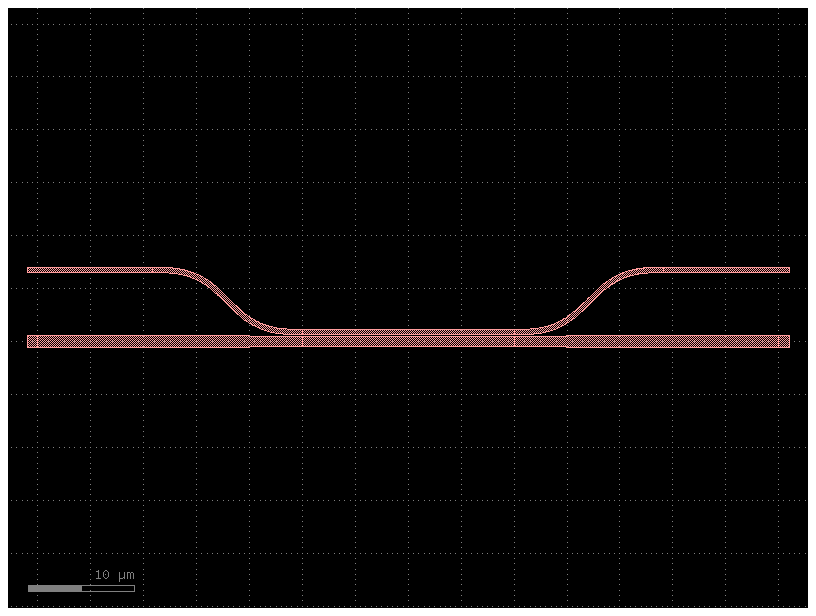

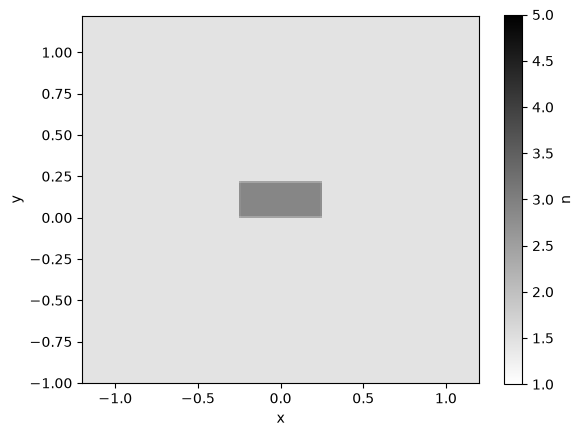

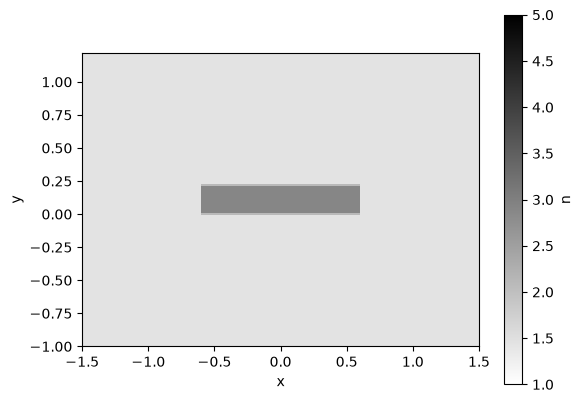

using simulation folder runs/mc_nres15


backend using simulation folder runs/mc_nres15


setting up simulation...


processing geometry bodies...


generating voxels...


voxelation: 56.549142 seconds (5.86 G allocations: 211.742 GiB, 42.24% gc time, 54.33% compilation time)


... (47 outputs left out)

period 380, decay: 0.0, 0.85 seconds/period, 8118.02 Mcells/s


period 380.68 stop on energy decay
8082.85 Mcells/s


simulation completed.


{'runtime': 532.9318134784698, 'gpu_GB': 25.8603515625, 'host_GB': 10.239059448242188}


In [4]:
for nres in nres_list:
    path = os.path.join("runs", f"mc_nres{nres}")
    setup(path, nres)
    print(solve_with_stats(path))

## Mode identification

In [5]:
def classify(path, frame="mm", wl=1.55):
    """per solved mode: TE fraction (lateral E energy) and lateral parity of the dominant E (+1 even, -1 odd)"""
    out = []
    for i in range(nmodes_mm):
        d = np.load(os.path.join(path, "modes", frame, str(wl), f"{i}.npz"))
        ex, ey = d["Ex"], d["Ey"]
        te = (abs(ex) ** 2).sum() / ((abs(ex) ** 2).sum() + (abs(ey) ** 2).sum())
        a = ex if te > 0.5 else ey
        parity = np.real(np.vdot(a, a[::-1, :])) / np.real(np.vdot(a, a))
        out.append((te, parity))
    return out


def te_modes(path):
    """indices of TE0 (TE-like, even) and TE1 (TE-like, odd) at the wide port"""
    c = classify(path)
    for i, (te, par) in enumerate(c):
        print(f"mode {i}: TE fraction {te:.3f}, parity {par:+.2f}")
    te0 = next(i for i, (te, par) in enumerate(c) if te > 0.5 and par > 0)
    te1 = next(i for i, (te, par) in enumerate(c) if te > 0.5 and par < 0)
    return te0, te1


te0, te1 = te_modes(os.path.join("runs", f"mc_nres{nres_list[0]}"))
print(f"TE0 = mode {te0}, TE1 = mode {te1}")

mode 0: TE fraction 0.985, parity +1.00
mode 1: TE fraction 0.931, parity -1.00
mode 2: TE fraction 0.038, parity +1.00
TE0 = mode 0, TE1 = mode 1


## Results

mode 0: TE fraction 0.990, parity +1.00
mode 1: TE fraction 0.955, parity -1.00
mode 2: TE fraction 0.038, parity +1.00
loading solution from runs/mc_nres6
may take a minute if simulation folder is remotely mounted
mode 0: TE fraction 0.999, parity +1.00
mode 1: TE fraction 0.995, parity -1.00
mode 2: TE fraction 0.975, parity +1.00
loading solution from runs/mc_nres10
may take a minute if simulation folder is remotely mounted
mode 0: TE fraction 0.985, parity +1.00
mode 1: TE fraction 0.931, parity -1.00
mode 2: TE fraction 0.038, parity +1.00
loading solution from runs/mc_nres15
may take a minute if simulation folder is remotely mounted
nres  TE1 cross  crosstalk  through  reflect  runtime  GPU mem  host mem
   6      0.502   -59.6 dB    0.407   0.0061    146 s  12.39 GB   2.60 GB
  10      0.510   -34.3 dB    0.431   0.0055    229 s  12.37 GB   4.56 GB
  15      0.456   -33.9 dB    0.495   0.0028    533 s  25.86 GB  10.24 GB


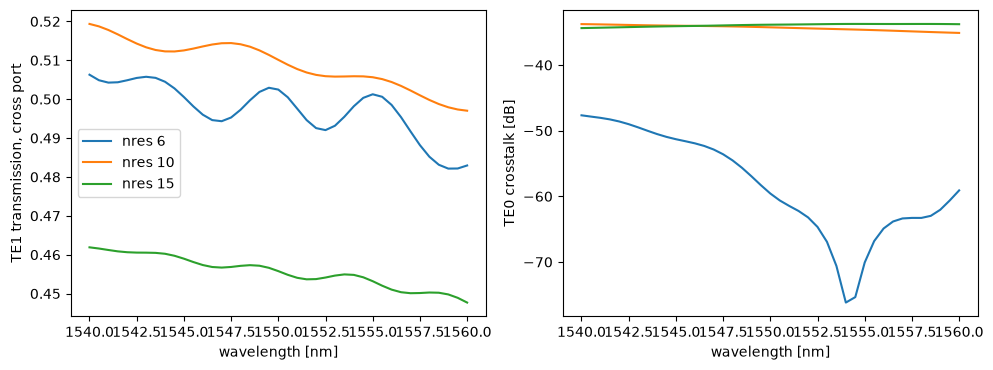

In [6]:
wls_nm = 1000 * np.array(wavelengths)
i0 = np.argmin(abs(wls_nm - 1550))
rows = []
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for nres in [6, 10, 15, 20, 25]:
    path = os.path.join("runs", f"mc_nres{nres}")
    if not os.path.exists(os.path.join(path, "solution.json")):
        continue
    k0, k1 = te_modes(path)
    m = lumi.load(path)["monitors"]
    a = np.array(m["o2"]["modes"][0]["-"])
    T1 = np.abs(np.array(m["o3"]["modes"][k1]["+"]) / a) ** 2  # TE1, cross port
    X = 10 * np.log10(np.abs(np.array(m["o3"]["modes"][k0]["+"]) / a) ** 2)  # TE0 crosstalk, cross port
    Tt = np.abs(np.array(m["o4"]["modes"][0]["+"]) / a) ** 2  # TE0, through port
    R = np.abs(np.array(m["o2"]["modes"][0]["+"]) / a) ** 2
    f = os.path.join(path, "stats.json")
    st = json.load(open(f)) if os.path.exists(f) else {}
    rows.append((nres, T1[i0], X[i0], Tt[i0], R[i0], st.get("runtime"), st.get("gpu_GB"), st.get("host_GB")))
    ax[0].plot(wls_nm, T1, label=f"nres {nres}")
    ax[1].plot(wls_nm, X, label=f"nres {nres}")

fmt = lambda v, f: "–" if v is None else format(v, f)
print("nres  TE1 cross  crosstalk  through  reflect  runtime  GPU mem  host mem")
for nres, t1, x, tt, r, rt, g, h in rows:
    print(f"{nres:4d}  {t1:9.3f}  {x:6.1f} dB  {tt:7.3f}  {r:7.4f}  {fmt(rt, '5.0f'):>5} s  {fmt(g, '5.2f'):>5} GB  {fmt(h, '5.2f'):>5} GB")

ax[0].set(xlabel="wavelength [nm]", ylabel="TE1 transmission, cross port")
ax[1].set(xlabel="wavelength [nm]", ylabel="TE0 crosstalk [dB]")
ax[0].legend()
plt.tight_layout()
plt.show()

## Fig. 16a, c comparison

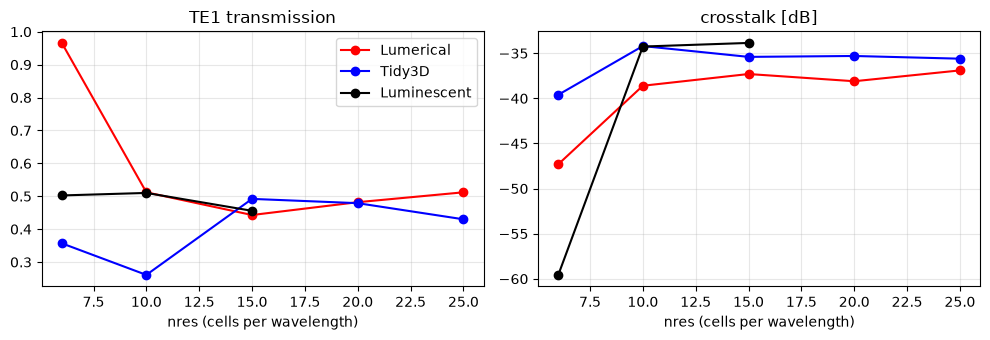

In [7]:
# paper Fig. 16a, c, digitized
nres_paper = [6, 10, 15, 20, 25]
paper = {
    "TE1 transmission": ([0.357, 0.261, 0.492, 0.479, 0.430], [0.966, 0.512, 0.443, 0.482, 0.512]),
    "crosstalk [dB]": ([-39.6, -34.2, -35.4, -35.3, -35.6], [-47.3, -38.6, -37.3, -38.1, -36.9]),
}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
for a, (name, (tidy3d, lumerical)), col in zip(ax, paper.items(), [1, 2]):
    a.plot(nres_paper, lumerical, "o-", color="red", label="Lumerical")
    a.plot(nres_paper, tidy3d, "o-", color="blue", label="Tidy3D")
    a.plot([r[0] for r in rows], [r[col] for r in rows], "o-", color="black", label="Luminescent")
    a.set(xlabel="nres (cells per wavelength)", title=name)
    a.grid(alpha=0.3)
ax[0].legend()
plt.tight_layout()
plt.show()

## Movie

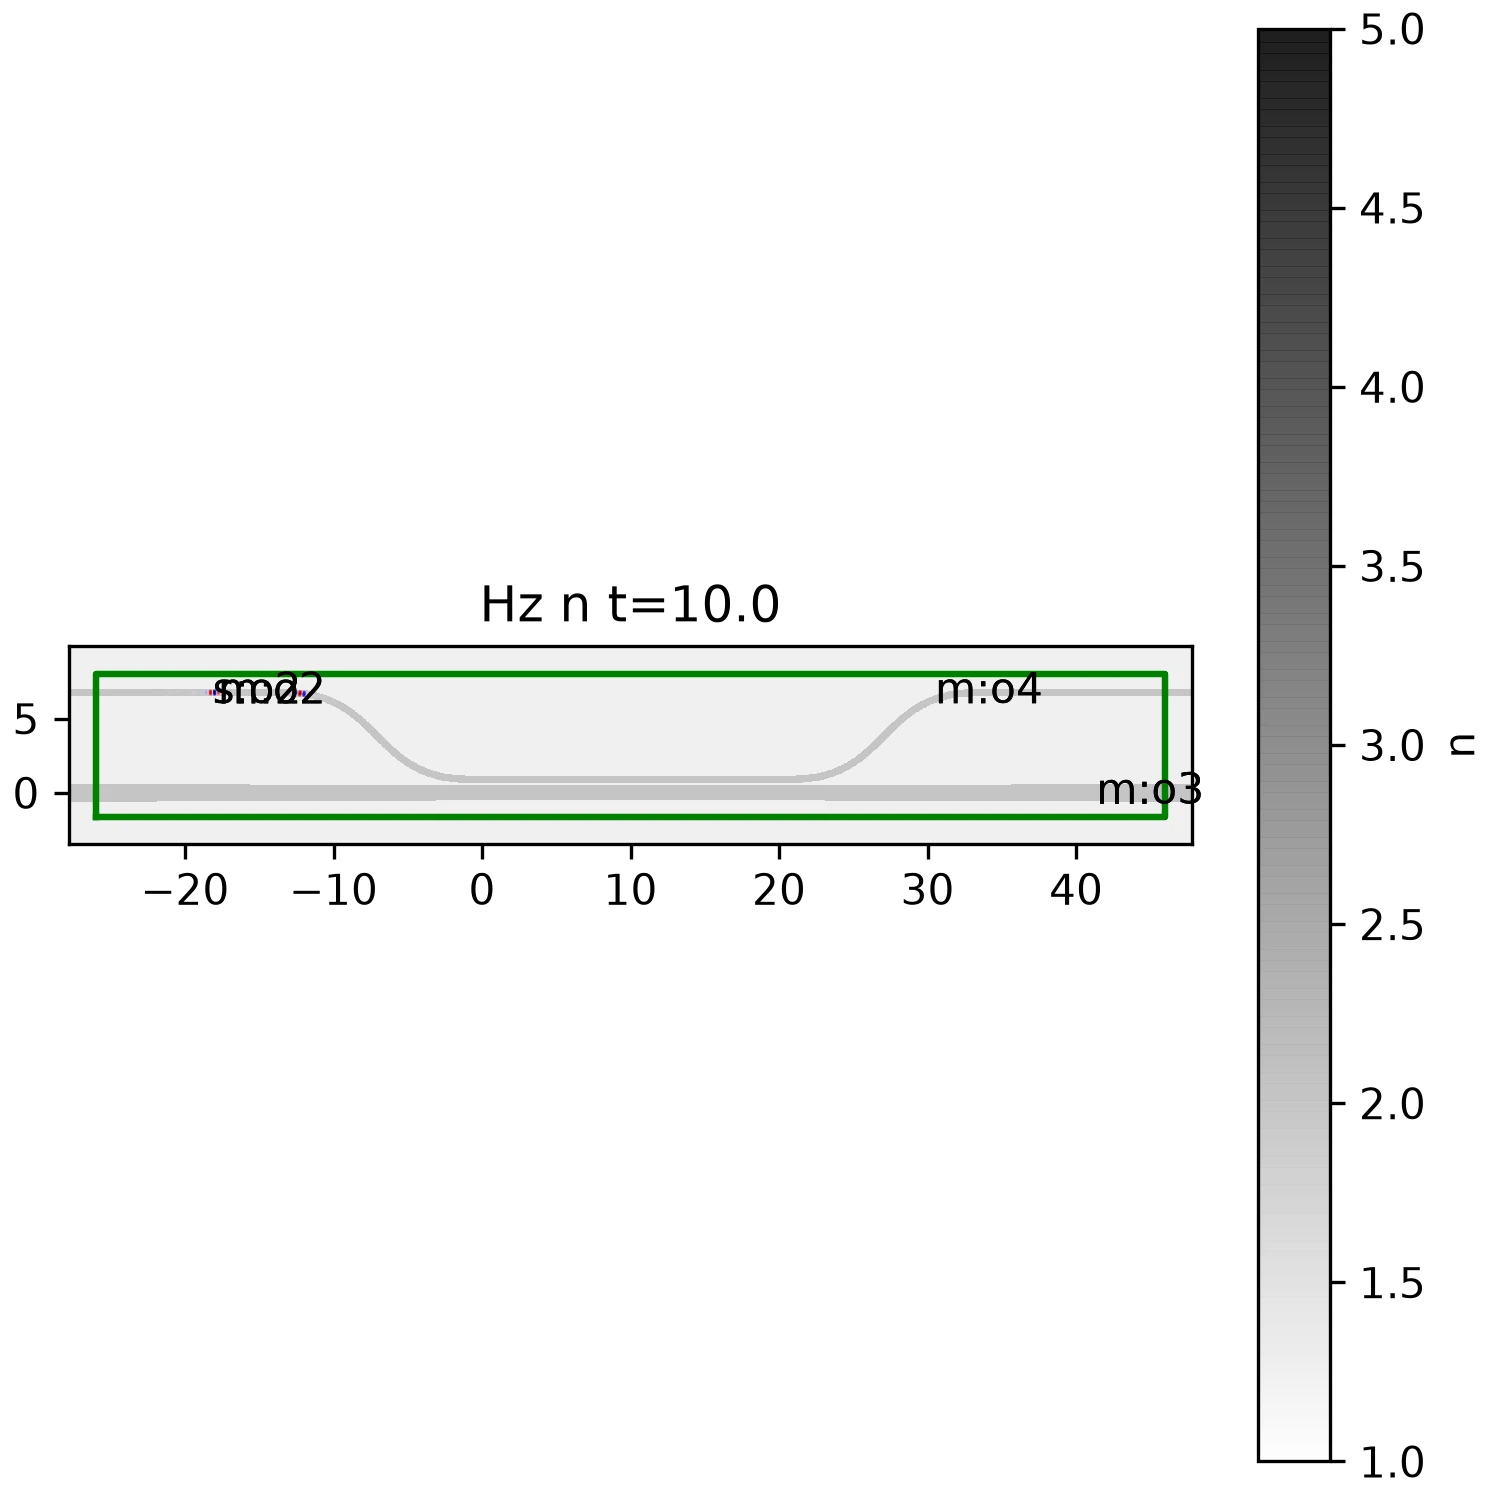

In [8]:
lumi.movie(os.path.join("runs", f"mc_nres{nres_list[-1]}"))